## Evaluation of XAI Experiment in Toloka

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy
from scipy.special import softmax
import os
import scienceplots
plt.style.use(['science', 'no-latex'])

stats_folder = './bees/' #'./beexplainable/toloka/bees/'
stats = {
    'Control': pd.read_csv(stats_folder + 'experiment_200_2/Toloka_Bees_Control_200_2_accepted.tsv',
                           sep = '\t'),
    'Control_Conf':pd.read_csv(stats_folder + 'experiment_200_2/Toloka_Bees_Control_Conf_200_2_accepted.tsv',
                           sep = '\t'),
    'Concepts_KNN':pd.read_csv(stats_folder + 'experiment_200_2/Toloka_Bees_Concepts_KNN_200_2_accepted.tsv',
                           sep = '\t'),
    'Concepts_TCAV':pd.read_csv(stats_folder + 'experiment_200_2/Toloka_Bees_Concepts_TCAV_200_2_accepted.tsv',
                           sep = '\t'),
    'Examples_GradSim':pd.read_csv(stats_folder + 'experiment_200_2/Toloka_Bees_Examples_GradSim_200_2_accepted.tsv',
                           sep = '\t'),
    'Examples_RepPoint':pd.read_csv(stats_folder + 'experiment_200_2/Toloka_Bees_Examples_RepPoint_200_2_accepted.tsv',
                           sep = '\t')
}

classes = np.array( ["Andrena bicolor", "Andrena flavipes", "Andrena fulva"] )
num_samples_per_task = 10.0

In [2]:
# How many different users are there?
# Note: banned users are not listed
num_users = {}
for group in stats:
    num_users[group] = stats[group]['ASSIGNMENT:assignment_id'].nunique()
    print(group + ' group has ' + str(num_users[group]) + ' accepted users.')

Control group has 140 accepted users.
Control_Conf group has 137 accepted users.
Concepts_KNN group has 141 accepted users.
Concepts_TCAV group has 144 accepted users.
Examples_GradSim group has 154 accepted users.
Examples_RepPoint group has 145 accepted users.


### User-Model Uncertainty-Accuracy-Agreement Correlations

In [3]:
import sys
sys.path.append('../beexplainable/utils')
import metafile_readers as mr

In [4]:
# Read metafiles
IMAGES_PATH = '../metafiles/Bees/masked/images_5_cleaned.txt'
img_dict = mr.metafile_to_dict(IMAGES_PATH)
CLASSES_PATH = '../metafiles/Bees/masked/5_species/classes.txt'
classes = mr.metafile_to_dict(CLASSES_PATH)
print(classes)
loaded_soft = np.load('../metafiles/Bees/masked/5_species/softmax_preds.npy')
print(str(len(loaded_soft)) + ' softmax vectors loaded.')

{'1': 'Andrena_bicolor', '2': 'Andrena_flavipes', '3': 'Andrena_fulva', '4': 'Bombus_lucorum', '5': 'Bombus_pratorum'}
5166 softmax vectors loaded.


In [5]:
# Read urls belonging to tasks 1/3 and task 2 images
import glob
IMG_LINKS = './bees/images/*.txt'
link_files = glob.glob(IMG_LINKS)
task13_link_files = link_files[-1]
task2_link_files  = [f.replace('\\', '/') for f in link_files][:-1]

t2_links = {}
groups_lower_case = [g.lower() for g in list(stats.keys())] # for index searching: link file names are all lower case

for t2_file in task2_link_files:
    group_lower_case = t2_file[26:-4] # extract group name
    group_ind = groups_lower_case.index(group_lower_case)
    group = list(stats.keys())[group_ind] # same format as in tsv

    with open(t2_file, 'r') as f:
        t2_links[group] = f.read().splitlines() # store lists of urls for every group (without '\n')

Get/Compute for every group (for Tasks 1/3 and Task 2 images): 

+ User Accuracy (frequency of clicking on the right class)
+ Model Accuracy (softmax probability of the true class)
+ Model Uncertainty (entropy in the softmax vector)
+ User Agreement with the model's prediction

In [6]:
# dict storing user-model accuracies and uncertainties for every group in control and xai tasks
uncert_points_per_group = {'Tasks 1+3': {}, 'Task 2': {}} 

for group in stats:
    uncert_points_per_group['Tasks 1+3'][group] = {'User_Acc': [], 'User_Agree': [], 'User_Uncert': [],
                                                   'Model_Acc': [], 'Model_Uncert': []}
    uncert_points_per_group['Task 2'][group]   = {'User_Acc': [], 'User_Agree': [], 'User_Uncert': [],
                                                  'Model_Acc': [], 'Model_Uncert': []}
    
    for img_url, rows_curr_img in stats[group].groupby(by='INPUT:image'):
       
        img_name = img_url.split('/')[-1]

        # Compute user acc. on this img (how often was this img classified correctly by users on average?)
        user_acc = np.count_nonzero( rows_curr_img['OUTPUT:result'] == rows_curr_img['GOLDEN:result'] )
        user_acc /= len(rows_curr_img)
        
        # Compute user uncertainty based on the distribution of the answers (softmax normalized)
        user_soft_vec = []
        for c in list(classes.values()):
            user_soft_vec.append( np.count_nonzero( rows_curr_img['OUTPUT:result'] == c.split('_')[1] ) )
        user_soft_vec = softmax( user_soft_vec )
        user_uncert = entropy( user_soft_vec )

        # Get model acc on this img (softmax prob. for the true class) and uncertainty (entropy in softmax vector)
        img_name_substrs = img_name.split('-')
        img_id, img_cls = img_name_substrs[2], img_name_substrs[0] + '_' + img_name_substrs[1]
        img_cls_ind = int( list(classes.keys())[list(classes.values()).index(img_cls)] ) - 1 # dict keys are 1-based       
        for key, val in img_dict.items():
            if img_id in val:
                img_soft_vec = loaded_soft[int(key)-1] # dict keys are 1-based                             
                break

        model_uncert = entropy(img_soft_vec)
        model_acc = img_soft_vec[img_cls_ind]               
        pred_cls_ind = np.argmax(img_soft_vec, axis=-1) 
        pred_spec = classes[str(pred_cls_ind+1)].split('_')[1] # get (only) species from 1-based predicted cls index
        user_agree = np.count_nonzero( rows_curr_img['OUTPUT:result'] == pred_spec ) / len(rows_curr_img)

        # Add uncertainties to dict
        if img_url in t2_links[group]: task_name = 'Task 2' 
        else: task_name = 'Tasks 1+3'
            
        uncert_points_per_group[task_name][group]['User_Acc'].append(user_acc)
        uncert_points_per_group[task_name][group]['User_Agree'].append(user_agree)
        uncert_points_per_group[task_name][group]['User_Uncert'].append(user_uncert)
        uncert_points_per_group[task_name][group]['Model_Acc'].append(model_acc)
        uncert_points_per_group[task_name][group]['Model_Uncert'].append(model_uncert)        

In [7]:
for m in ['User_Uncert', 'User_Agree']:
    for t in uncert_points_per_group:
        avg_list = []
        for g in stats:
            avg_list += uncert_points_per_group[t][g][m]
        s = np.mean(avg_list)
        print('Average ' + m + ' in ' + t + ': ' + str(np.round(s, 4)) + '\n')

Average User_Uncert in Tasks 1+3: 0.0359

Average User_Uncert in Task 2: 0.0151

Average User_Agree in Tasks 1+3: 0.5732

Average User_Agree in Task 2: 0.7187



C:\Users\Teo\AppData\Local\Temp/ipykernel_25760/1938848100.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../figures/toloka/acc_t2.png', bbox_inches='tight')


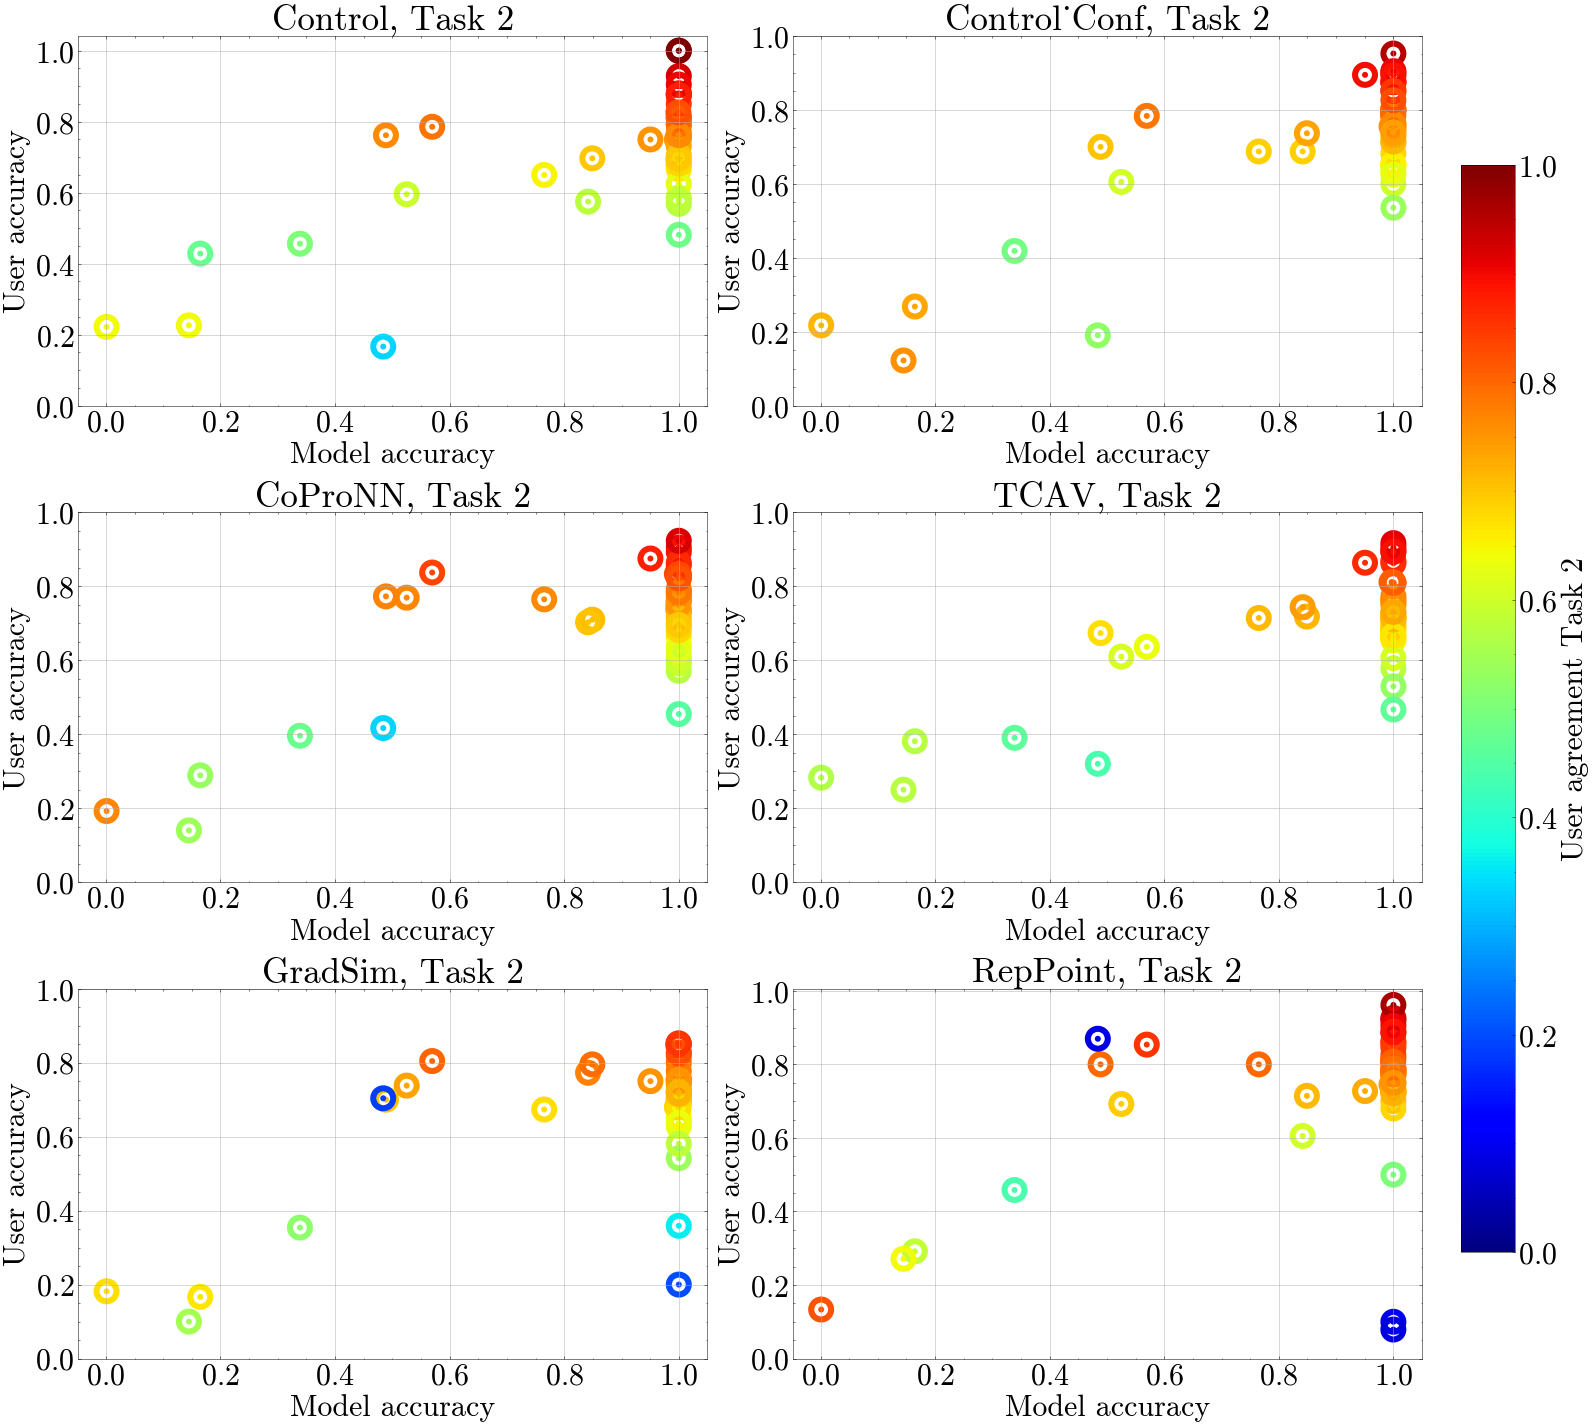

In [16]:
# Plot user_acc vs model_acc and user_agree color-coded (Task 2)
task_name = 'Task 2'
fontsize = 30
num_rows, num_cols = 3, 2
fig, axs = plt.subplots(num_rows, num_cols, figsize = (20,20), layout='tight')
norm = plt.Normalize(0.0, 1.0)

for i, group in enumerate(uncert_points_per_group[task_name]):
    plt.subplot(num_rows, num_cols, i+1)
    plt.scatter(y = uncert_points_per_group[task_name][group]['User_Acc'], 
                x = uncert_points_per_group[task_name][group]['Model_Acc'],
                c = plt.cm.jet(norm(uncert_points_per_group[task_name][group]['User_Agree'])), lw = 20)
    plt.ylabel('User accuracy', fontsize = fontsize); plt.xlabel('Model accuracy', fontsize = fontsize)
    plt.xticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    plt.yticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    if i < 2:
        plt.title(group + ', ' + task_name, fontsize = fontsize+5)
    elif i == 2:
        plt.title('CoProNN, ' + task_name, fontsize = fontsize+5)
    else:
        plt.title(group.split('_')[1] + ', ' + task_name, fontsize = fontsize+5)       
    plt.grid()
    
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.jet), ax = axs, 
                    orientation='vertical', location = 'right', anchor=(3.0, 0.0))
cbar.ax.tick_params(labelsize=fontsize)
cbar.set_label('User agreement Task 2', fontsize = fontsize)

plt.savefig('../figures/toloka/acc_t2.png', bbox_inches='tight')
plt.show()

C:\Users\Teo\AppData\Local\Temp/ipykernel_25760/1011459528.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../figures/toloka/acc_uncert_t2.png', bbox_inches='tight')


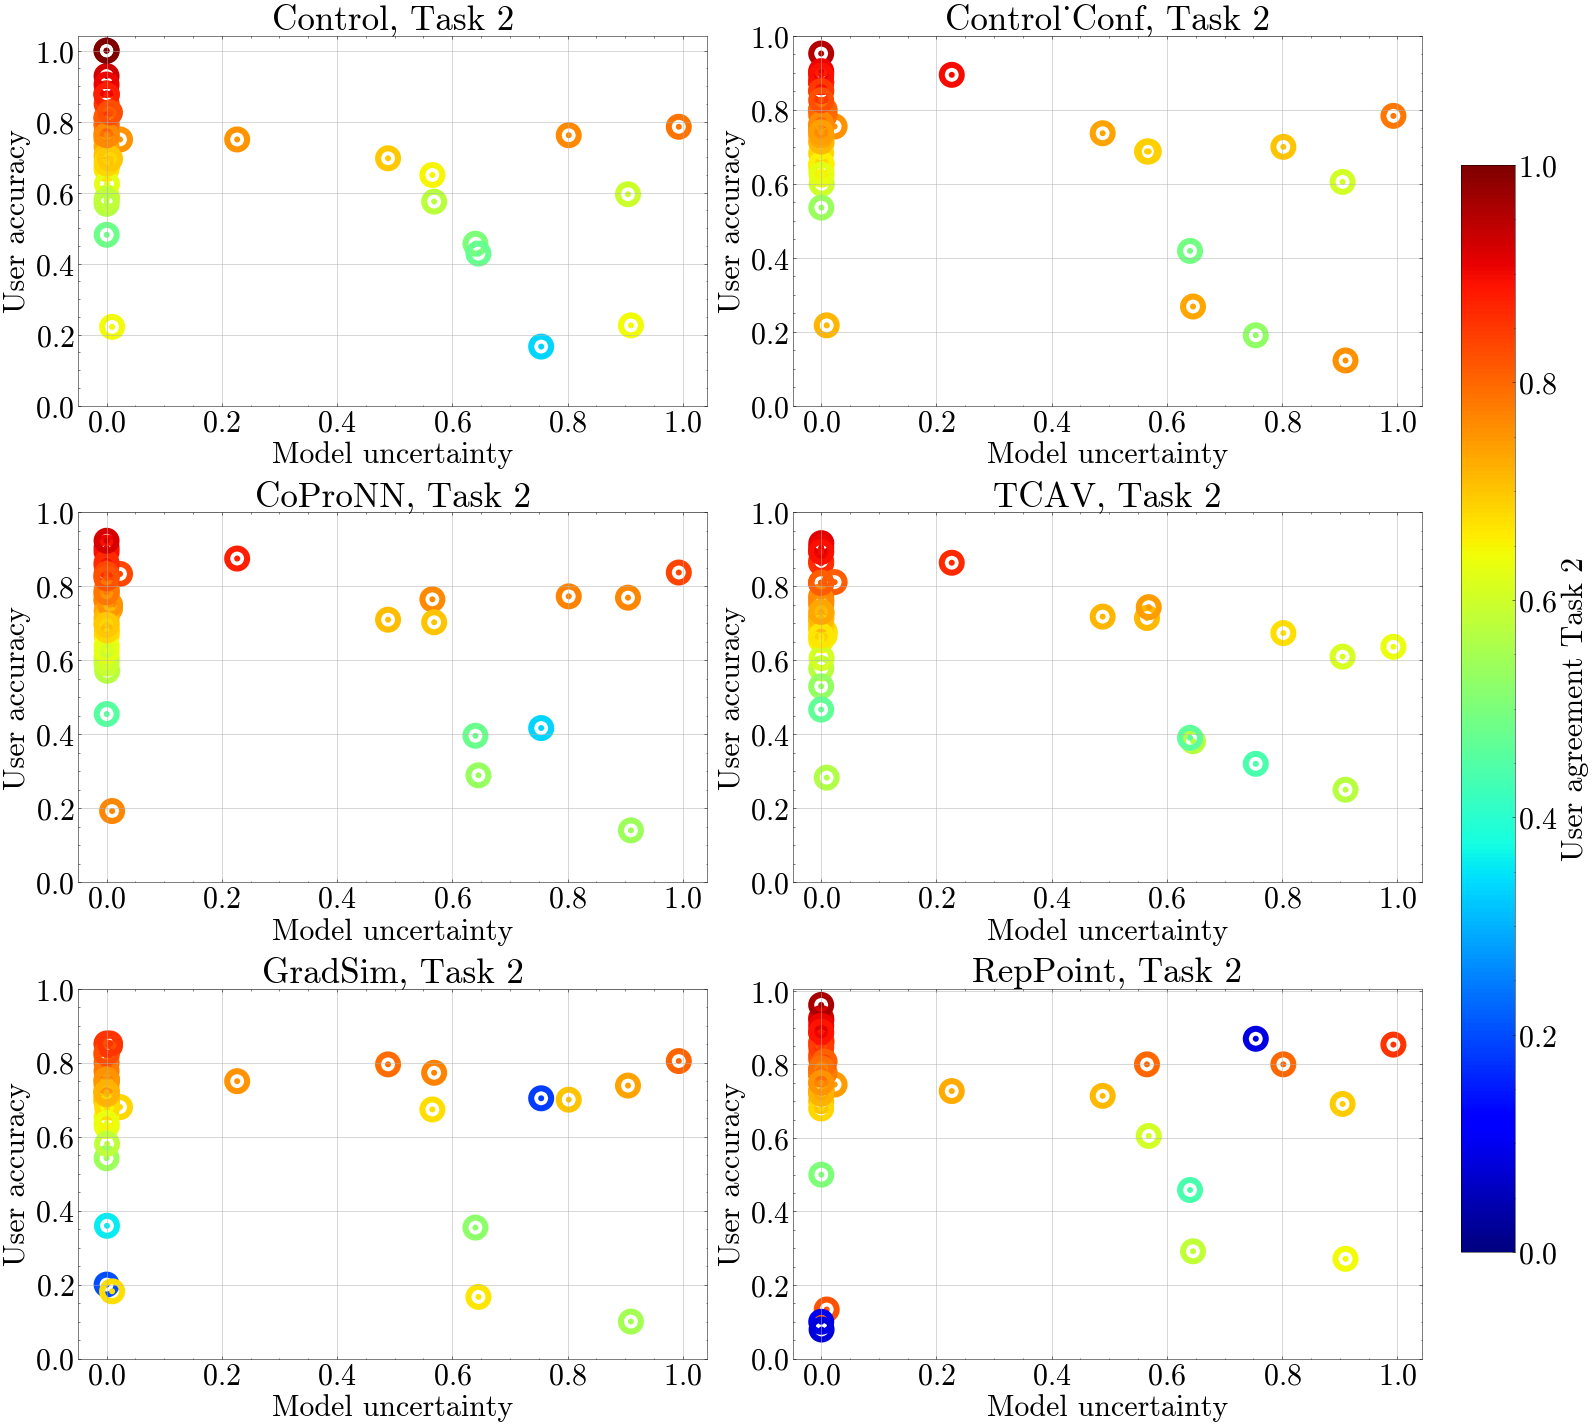

In [17]:
# Plot user_acc vs model_uncert and user_agree color-coded (Task 2)
task_name = 'Task 2'
fontsize = 30
num_rows, num_cols = 3, 2
fig, axs = plt.subplots(num_rows, num_cols, figsize = (20,20), layout='tight')
norm = plt.Normalize(0.0, 1.0)

for i, group in enumerate(uncert_points_per_group[task_name]):
    plt.subplot(num_rows, num_cols, i+1)
    plt.scatter(y = uncert_points_per_group[task_name][group]['User_Acc'], 
                x = uncert_points_per_group[task_name][group]['Model_Uncert'],
                c = plt.cm.jet(norm(uncert_points_per_group[task_name][group]['User_Agree'])), lw = 20)
    plt.ylabel('User accuracy', fontsize = fontsize); plt.xlabel('Model uncertainty', fontsize = fontsize)
    plt.xticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    plt.yticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    if i < 2:
        plt.title(group + ', ' + task_name, fontsize = fontsize+5)
    elif i == 2:
        plt.title('CoProNN, ' + task_name, fontsize = fontsize+5)
    else:
        plt.title(group.split('_')[1] + ', ' + task_name, fontsize = fontsize+5) 
    plt.grid()
    
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.jet), ax = axs, 
                    orientation='vertical', location = 'right', anchor=(3.0, 0.0))
cbar.ax.tick_params(labelsize=fontsize)
cbar.set_label('User agreement Task 2', fontsize = fontsize)

plt.savefig('../figures/toloka/acc_uncert_t2.png', bbox_inches='tight')
plt.show()

C:\Users\Teo\AppData\Local\Temp/ipykernel_25760/1836937328.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../figures/toloka/uncert_t2.png', bbox_inches='tight')


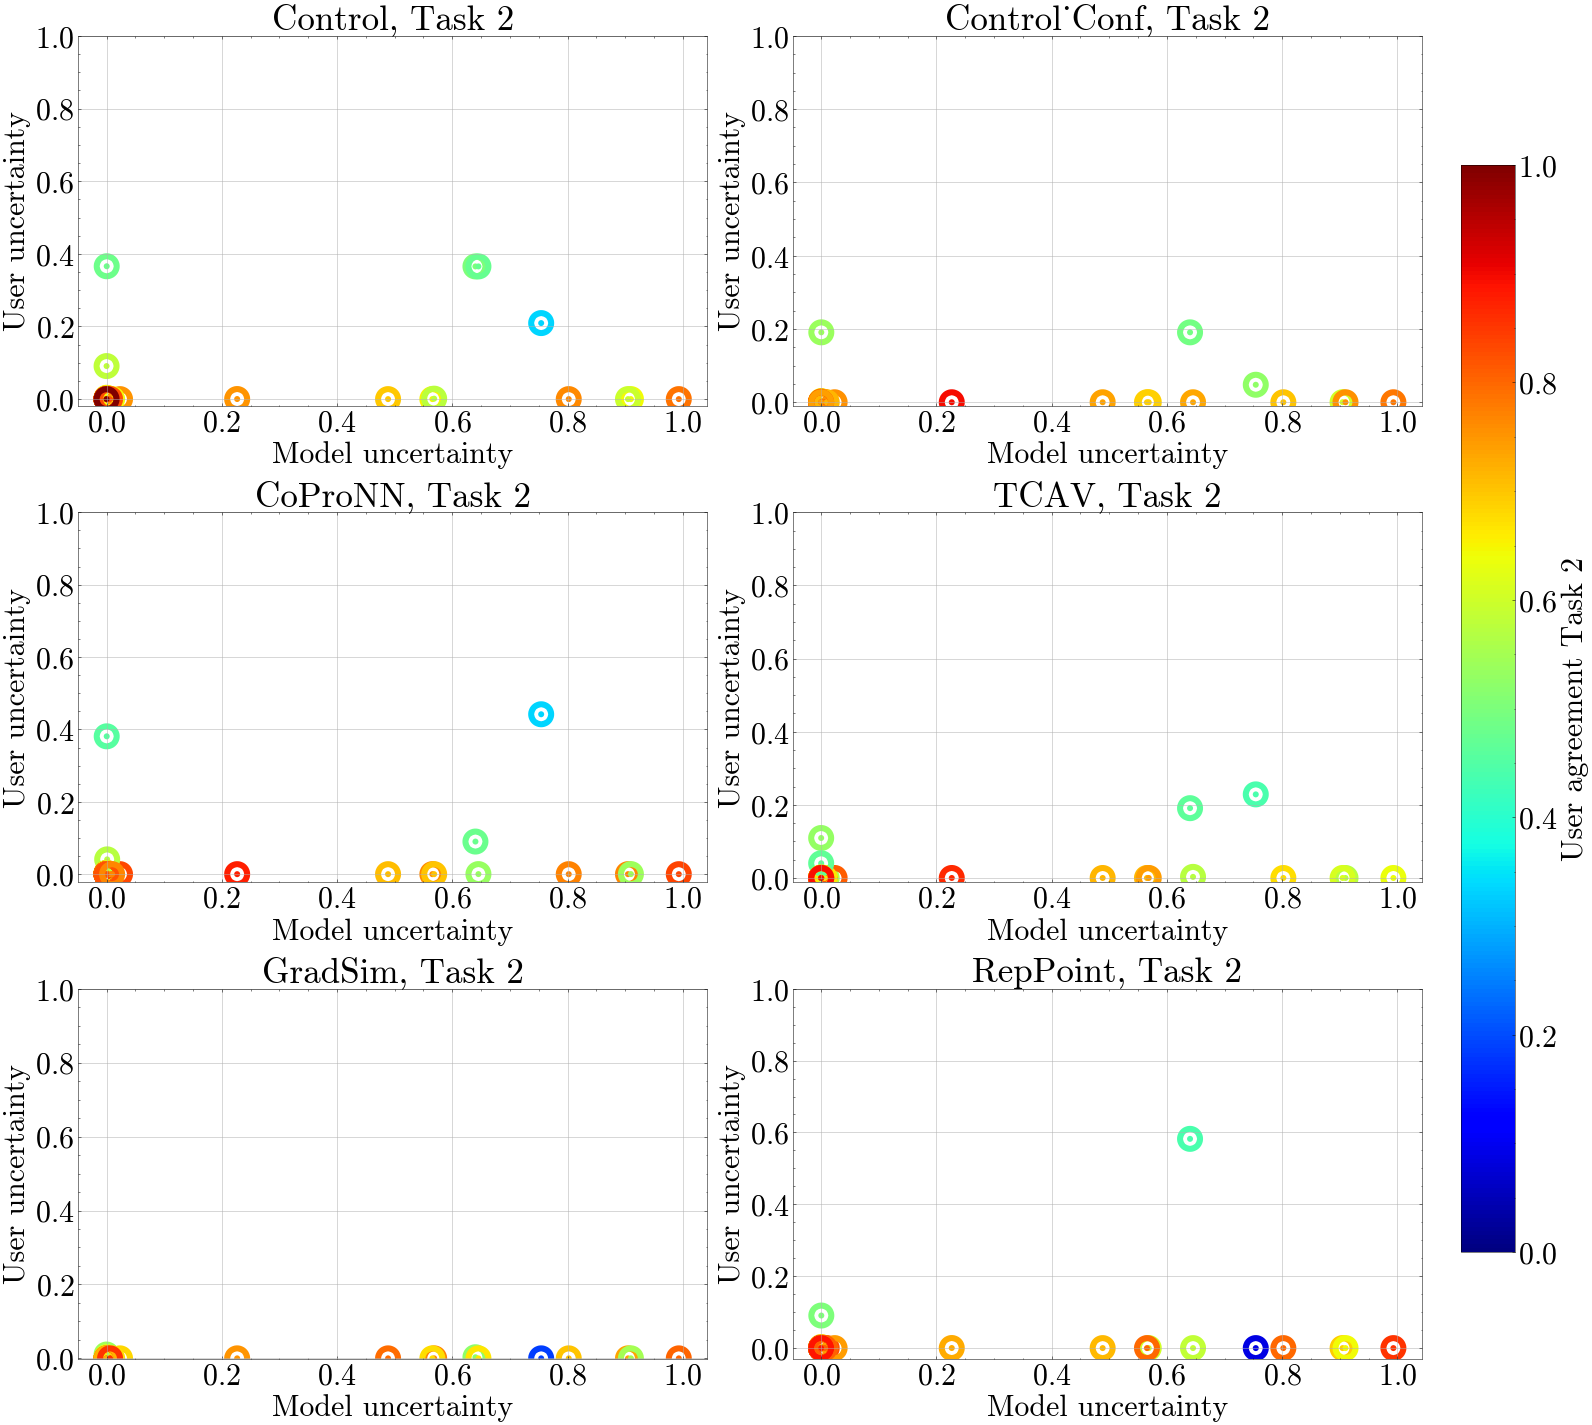

In [18]:
# Plot user_uncert vs model_uncert and user_agree color-coded (Task 2)
task_name = 'Task 2'
fontsize = 30
num_rows, num_cols = 3, 2
fig, axs = plt.subplots(num_rows, num_cols, figsize = (20,20), layout='tight')
norm = plt.Normalize(0.0, 1.0)

for i, group in enumerate(uncert_points_per_group[task_name]):
    plt.subplot(num_rows, num_cols, i+1)
    plt.scatter(y = uncert_points_per_group[task_name][group]['User_Uncert'], 
                x = uncert_points_per_group[task_name][group]['Model_Uncert'],
                c = plt.cm.jet(norm(uncert_points_per_group[task_name][group]['User_Agree'])), lw = 20)
    plt.ylabel('User uncertainty', fontsize = fontsize); plt.xlabel('Model uncertainty', fontsize = fontsize)
    plt.xticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    plt.yticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    if i < 2:
        plt.title(group + ', ' + task_name, fontsize = fontsize+5)
    elif i == 2:
        plt.title('CoProNN, ' + task_name, fontsize = fontsize+5)
    else:
        plt.title(group.split('_')[1] + ', ' + task_name, fontsize = fontsize+5) 
    plt.grid()
    
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.jet), ax = axs, 
                    orientation='vertical', location = 'right', anchor=(3.0, 0.0))
cbar.ax.tick_params(labelsize=fontsize)
cbar.set_label('User agreement Task 2', fontsize = fontsize)

plt.savefig('../figures/toloka/uncert_t2.png', bbox_inches='tight')
plt.show()

C:\Users\Teo\AppData\Local\Temp/ipykernel_25760/2277479583.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../figures/toloka/acc_uncert_t13.png', bbox_inches='tight')


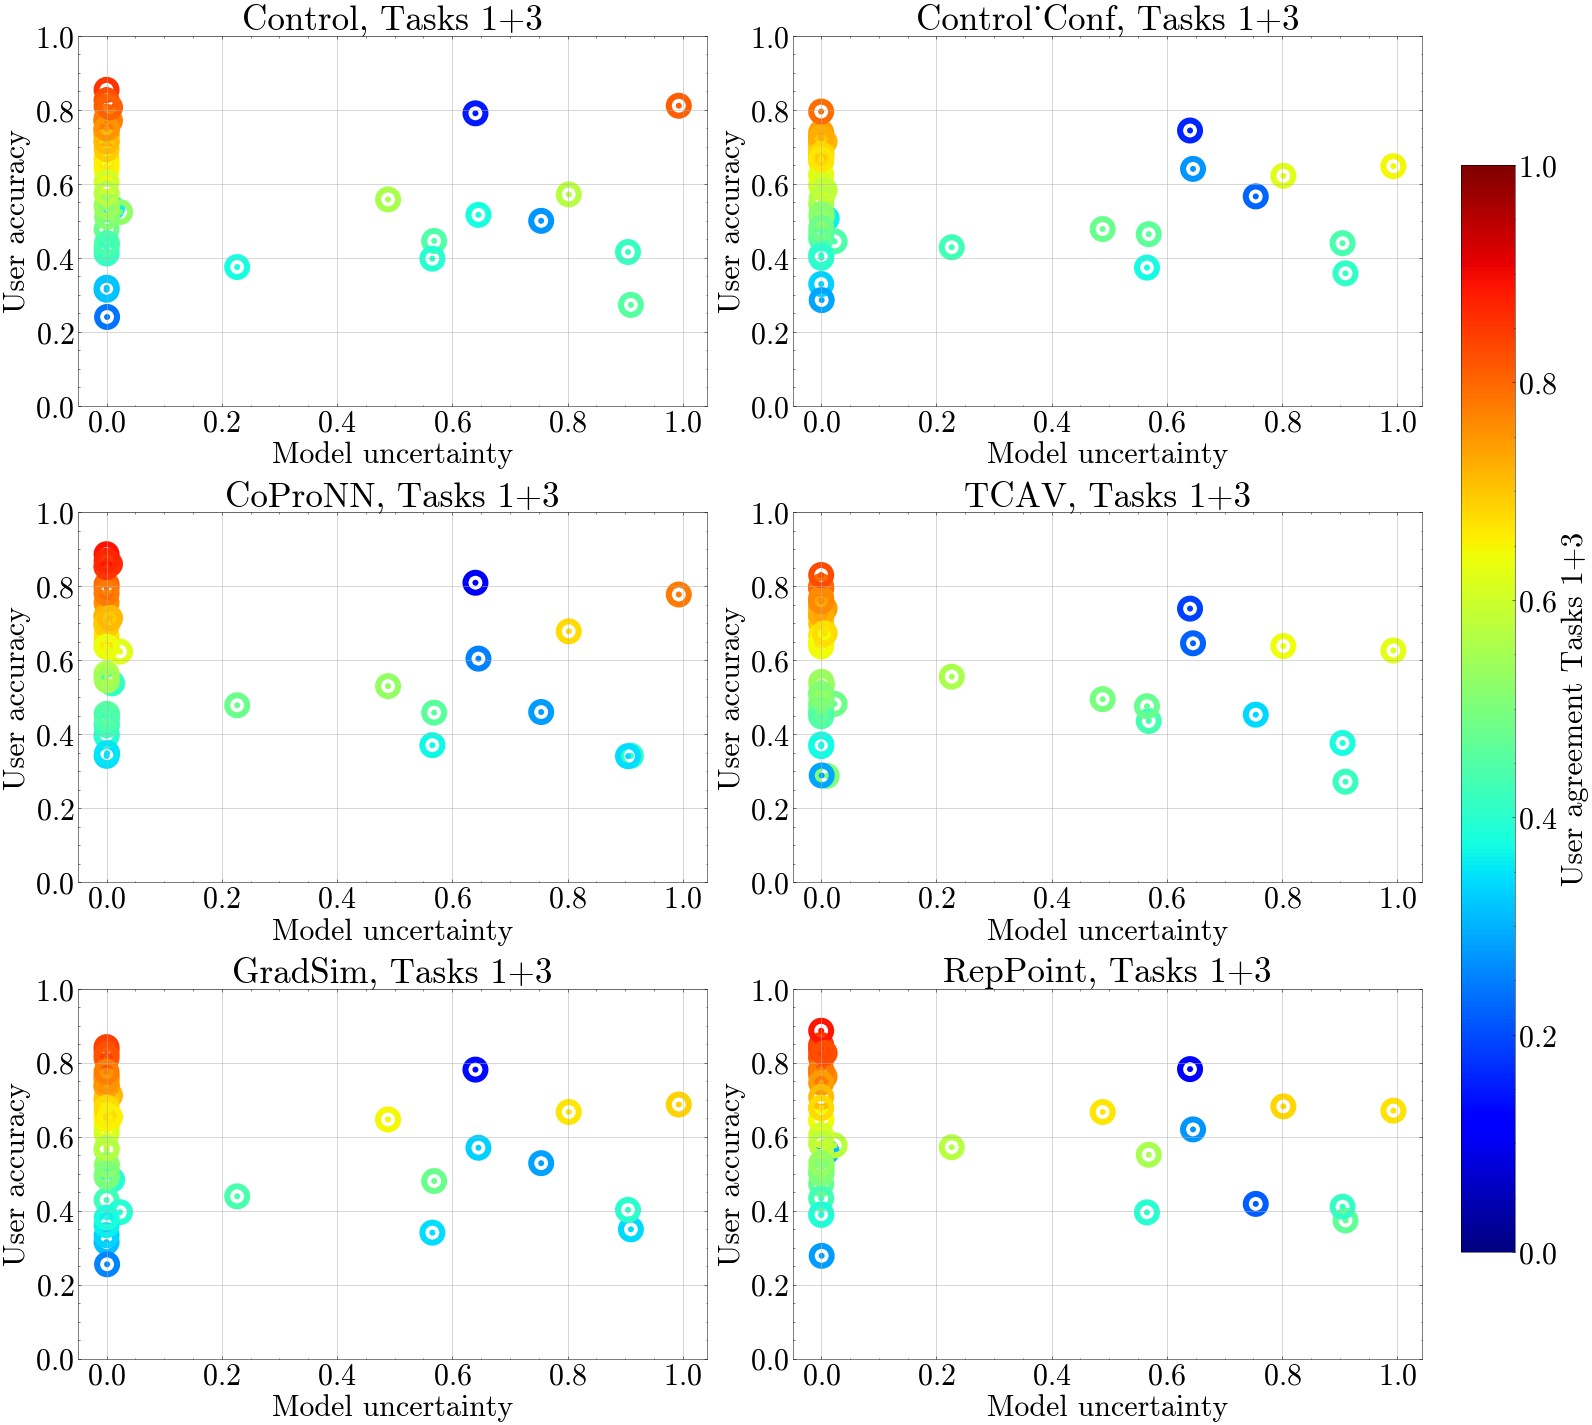

In [11]:
# Plot user_acc vs model_uncert and user_agree color-coded (Tasks 1 and 3)
task_name = 'Tasks 1+3'
fontsize = 30
num_rows, num_cols = 3, 2
fig, axs = plt.subplots(num_rows, num_cols, figsize = (20,20), layout='tight')
norm = plt.Normalize(0.0, 1.0)

for i, group in enumerate(uncert_points_per_group[task_name]):
    plt.subplot(num_rows, num_cols, i+1)
    plt.scatter(y = uncert_points_per_group[task_name][group]['User_Acc'], 
                x = uncert_points_per_group[task_name][group]['Model_Uncert'],
                c = plt.cm.jet(norm(uncert_points_per_group[task_name][group]['User_Agree'])), lw = 20)
    plt.ylabel('User accuracy', fontsize = fontsize); plt.xlabel('Model uncertainty', fontsize = fontsize)
    plt.xticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    plt.yticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    if i < 2:
        plt.title(group + ', ' + task_name, fontsize = fontsize+5)
    elif i == 2:
        plt.title('CoProNN, ' + task_name, fontsize = fontsize+5)
    else:
        plt.title(group.split('_')[1] + ', ' + task_name, fontsize = fontsize+5) 
    plt.grid()
    
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.jet), ax = axs, 
                    orientation='vertical', location = 'right', anchor=(3.0, 0.0))
cbar.ax.tick_params(labelsize=fontsize)
cbar.set_label('User agreement ' + task_name, fontsize = fontsize)

plt.savefig('../figures/toloka/acc_uncert_t13.png', bbox_inches='tight')
plt.show()

C:\Users\Teo\AppData\Local\Temp/ipykernel_25760/201085543.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../figures/toloka/uncert_t13.png', bbox_inches='tight')


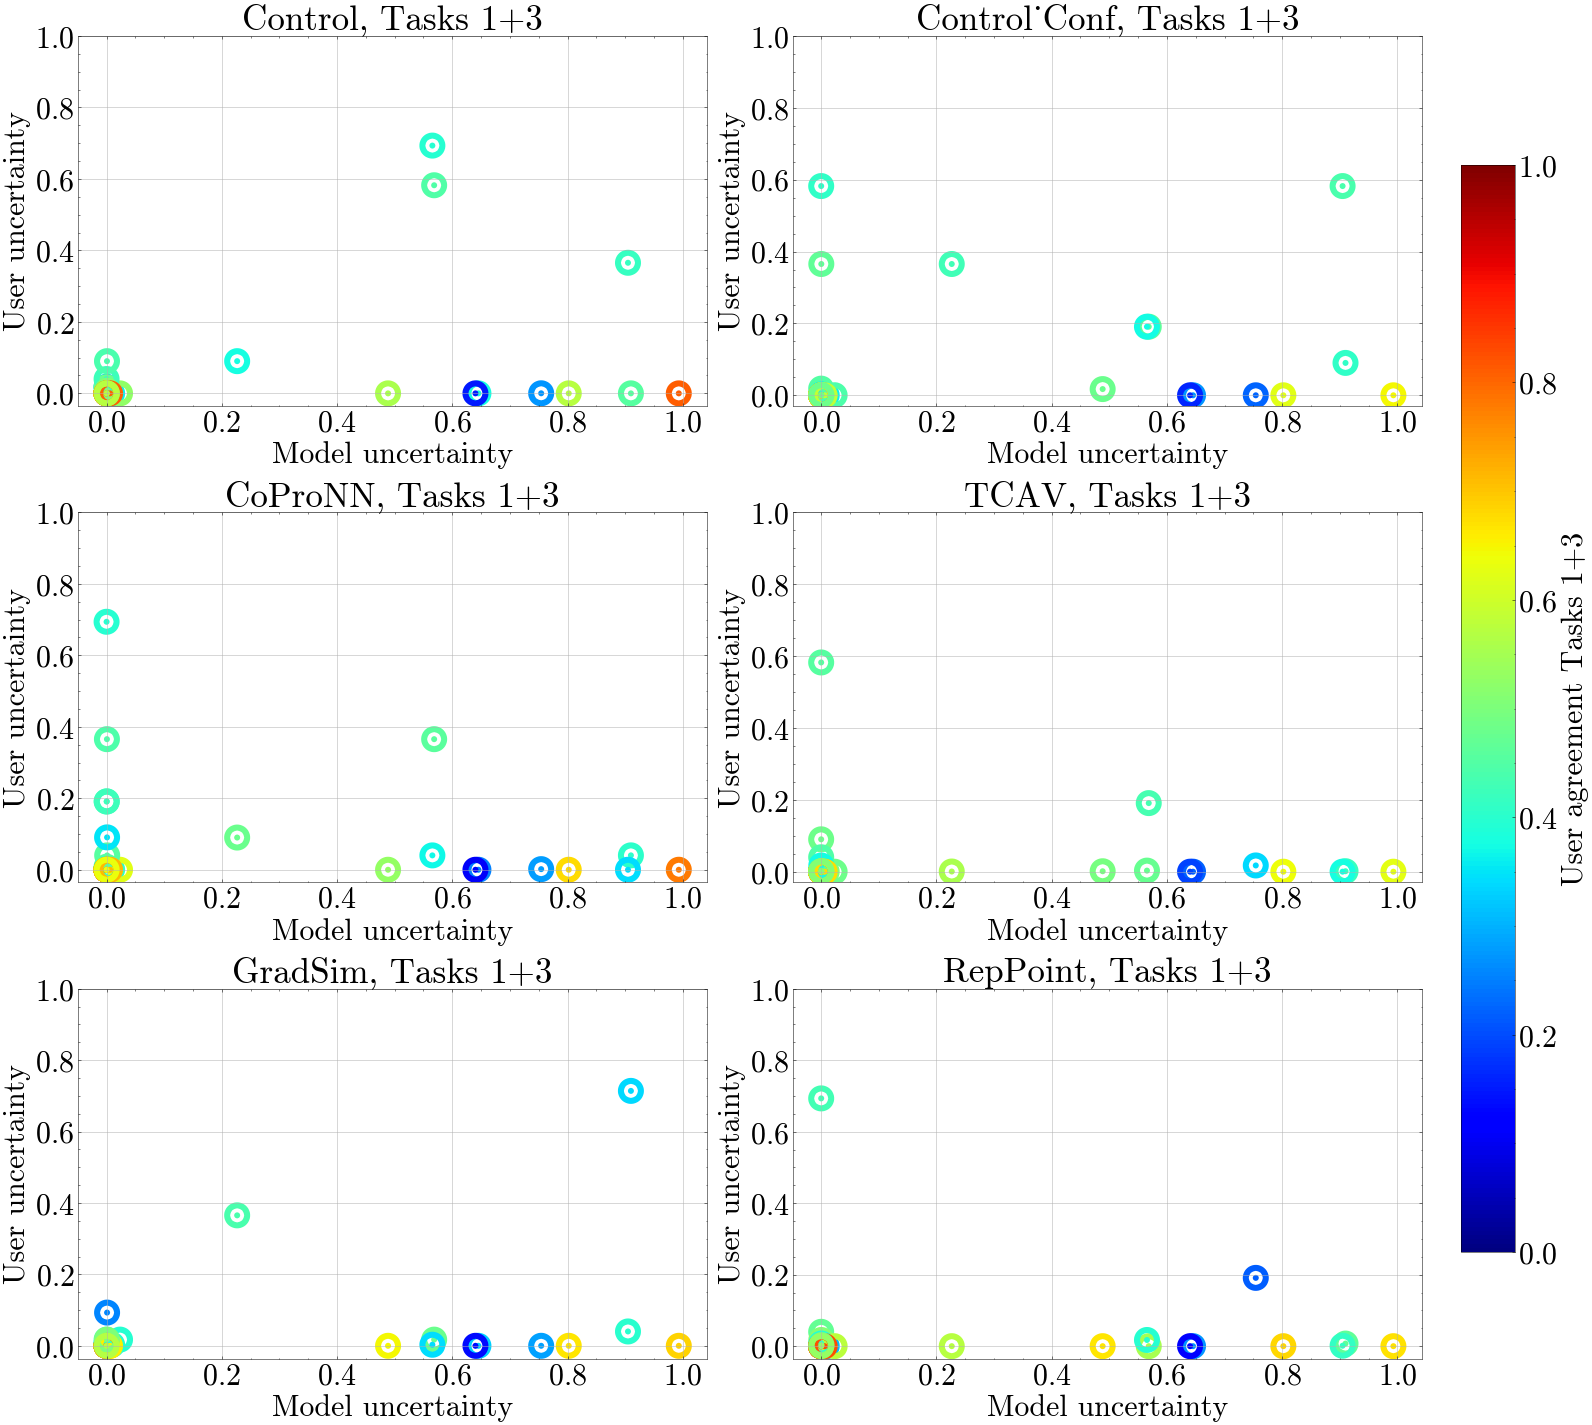

In [12]:
# Plot user_uncert vs model_uncert and user_agree color-coded (Tasks 1 and 3)
task_name = 'Tasks 1+3'
fontsize = 30
num_rows, num_cols = 3, 2
fig, axs = plt.subplots(num_rows, num_cols, figsize = (20,20), layout='tight')
norm = plt.Normalize(0.0, 1.0)

for i, group in enumerate(uncert_points_per_group[task_name]):
    plt.subplot(num_rows, num_cols, i+1)
    plt.scatter(y = uncert_points_per_group[task_name][group]['User_Uncert'], 
                x = uncert_points_per_group[task_name][group]['Model_Uncert'],
                c = plt.cm.jet(norm(uncert_points_per_group[task_name][group]['User_Agree'])), lw = 20)
    plt.ylabel('User uncertainty', fontsize = fontsize); plt.xlabel('Model uncertainty', fontsize = fontsize)
    plt.xticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    plt.yticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    if i < 2:
        plt.title(group + ', ' + task_name, fontsize = fontsize+5)
    elif i == 2:
        plt.title('CoProNN, ' + task_name, fontsize = fontsize+5)
    else:
        plt.title(group.split('_')[1] + ', ' + task_name, fontsize = fontsize+5) 
    plt.grid()
    
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.jet), ax = axs, 
                    orientation='vertical', location = 'right', anchor=(3.0, 0.0))
cbar.ax.tick_params(labelsize=fontsize)
cbar.set_label('User agreement ' + task_name, fontsize = fontsize)

plt.savefig('../figures/toloka/uncert_t13.png', bbox_inches='tight')
plt.show()

C:\Users\Teo\AppData\Local\Temp/ipykernel_25760/3833119387.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../figures/toloka/acc_uncert_t13_acc_t2.png', bbox_inches='tight')


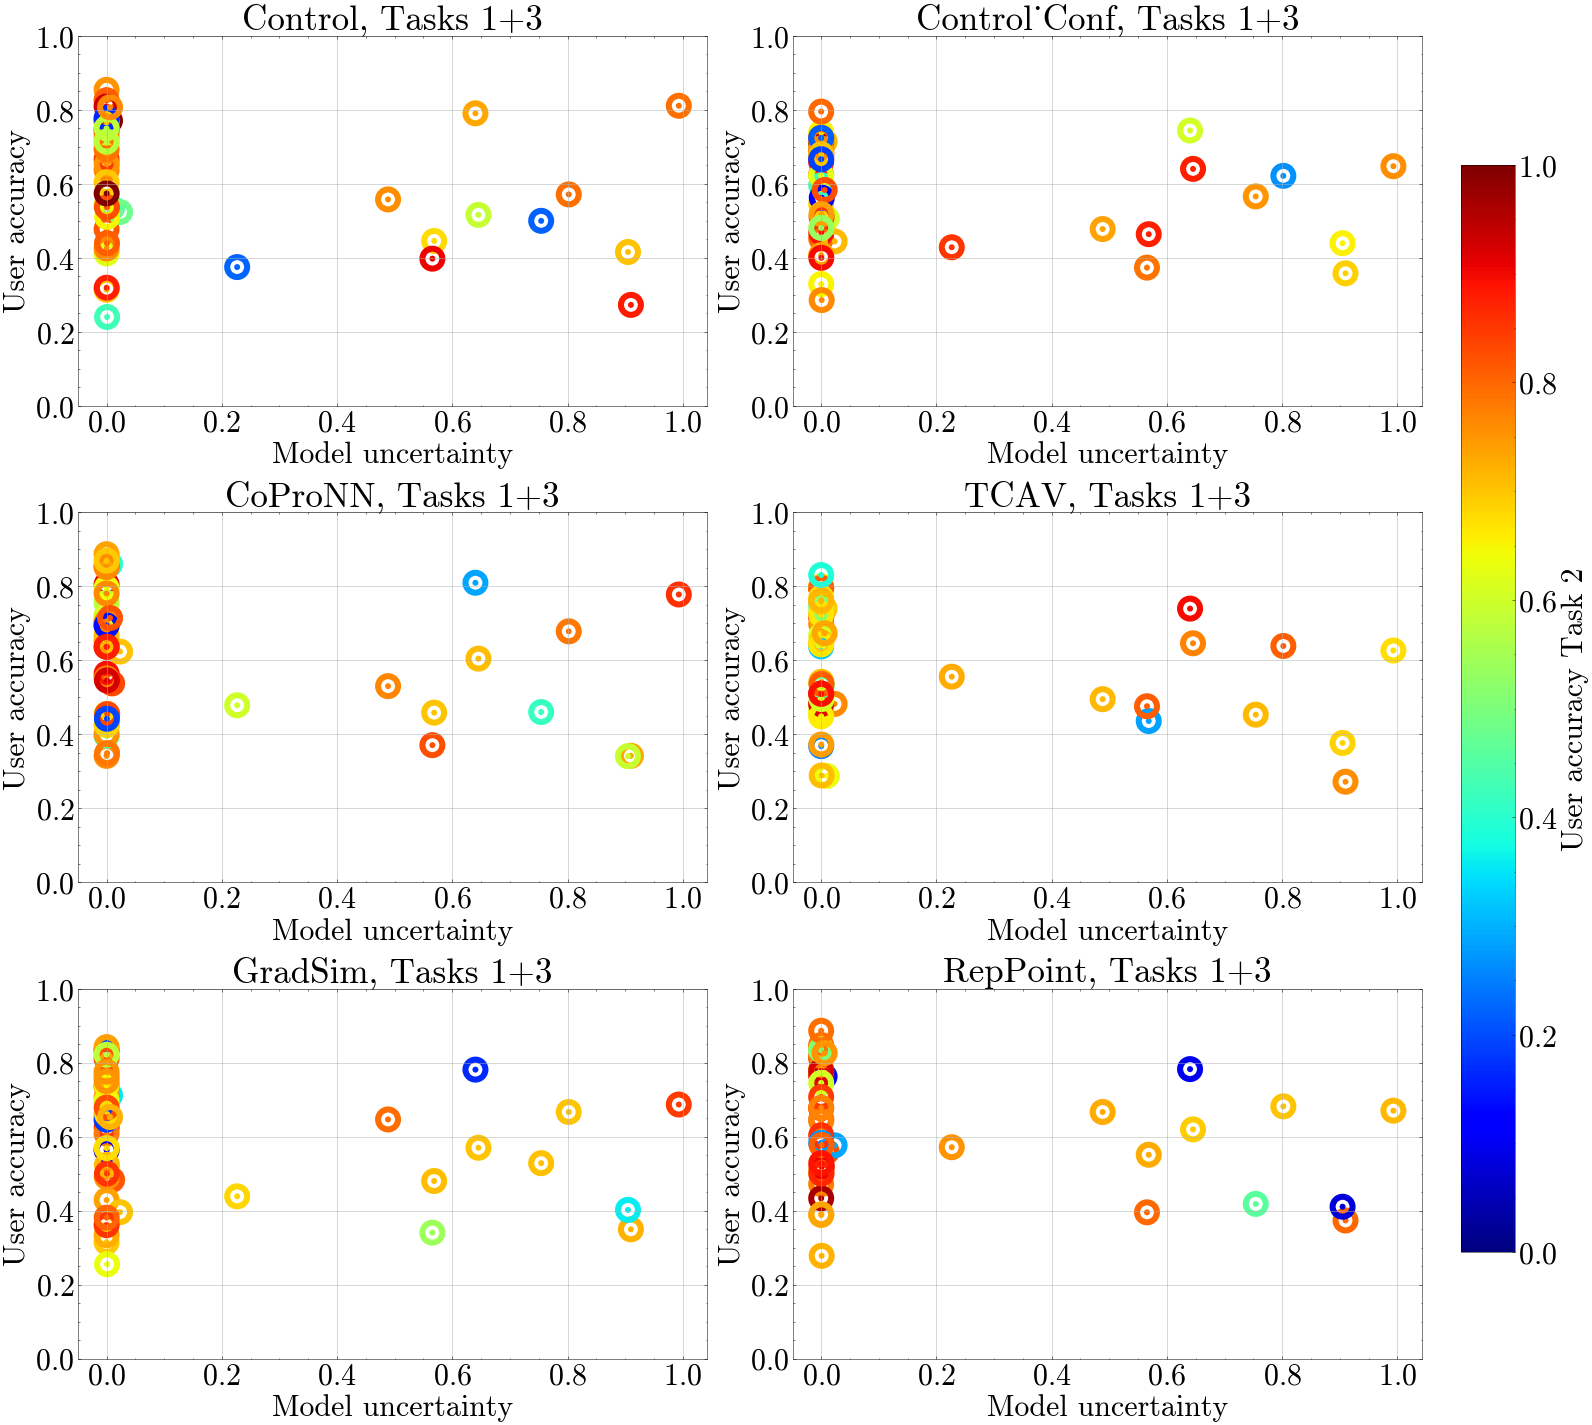

In [13]:
# Plot user_acc T13 vs model_uncert and user_acc T2 color-coded
task_name = 'Tasks 1+3'
fontsize = 30
num_rows, num_cols = 3, 2
fig, axs = plt.subplots(num_rows, num_cols, figsize = (20,20), layout='tight')
norm = plt.Normalize(0.0, 1.0)

for i, group in enumerate(uncert_points_per_group[task_name]):
    plt.subplot(num_rows, num_cols, i+1)
    plt.scatter(y = uncert_points_per_group[task_name][group]['User_Acc'], 
                x = uncert_points_per_group[task_name][group]['Model_Uncert'],
                c = plt.cm.jet(norm(uncert_points_per_group['Task 2'][group]['User_Acc'])), lw = 20)
    plt.ylabel('User accuracy', fontsize = fontsize)
    plt.xlabel('Model uncertainty', fontsize = fontsize)
    plt.xticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    plt.yticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    if i < 2:
        plt.title(group + ', ' + task_name, fontsize = fontsize+5)
    elif i == 2:
        plt.title('CoProNN, ' + task_name, fontsize = fontsize+5)
    else:
        plt.title(group.split('_')[1] + ', ' + task_name, fontsize = fontsize+5) 
    plt.grid()
    
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.jet), ax = axs, 
                    orientation='vertical', location = 'right', anchor=(3.0, 0.0))
cbar.ax.tick_params(labelsize=fontsize)
cbar.set_label('User accuracy Task 2', fontsize = fontsize)

plt.savefig('../figures/toloka/acc_uncert_t13_acc_t2.png', bbox_inches='tight')
plt.show()

C:\Users\Teo\AppData\Local\Temp/ipykernel_25760/2448604084.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../figures/toloka/user_acc.png', bbox_inches='tight')


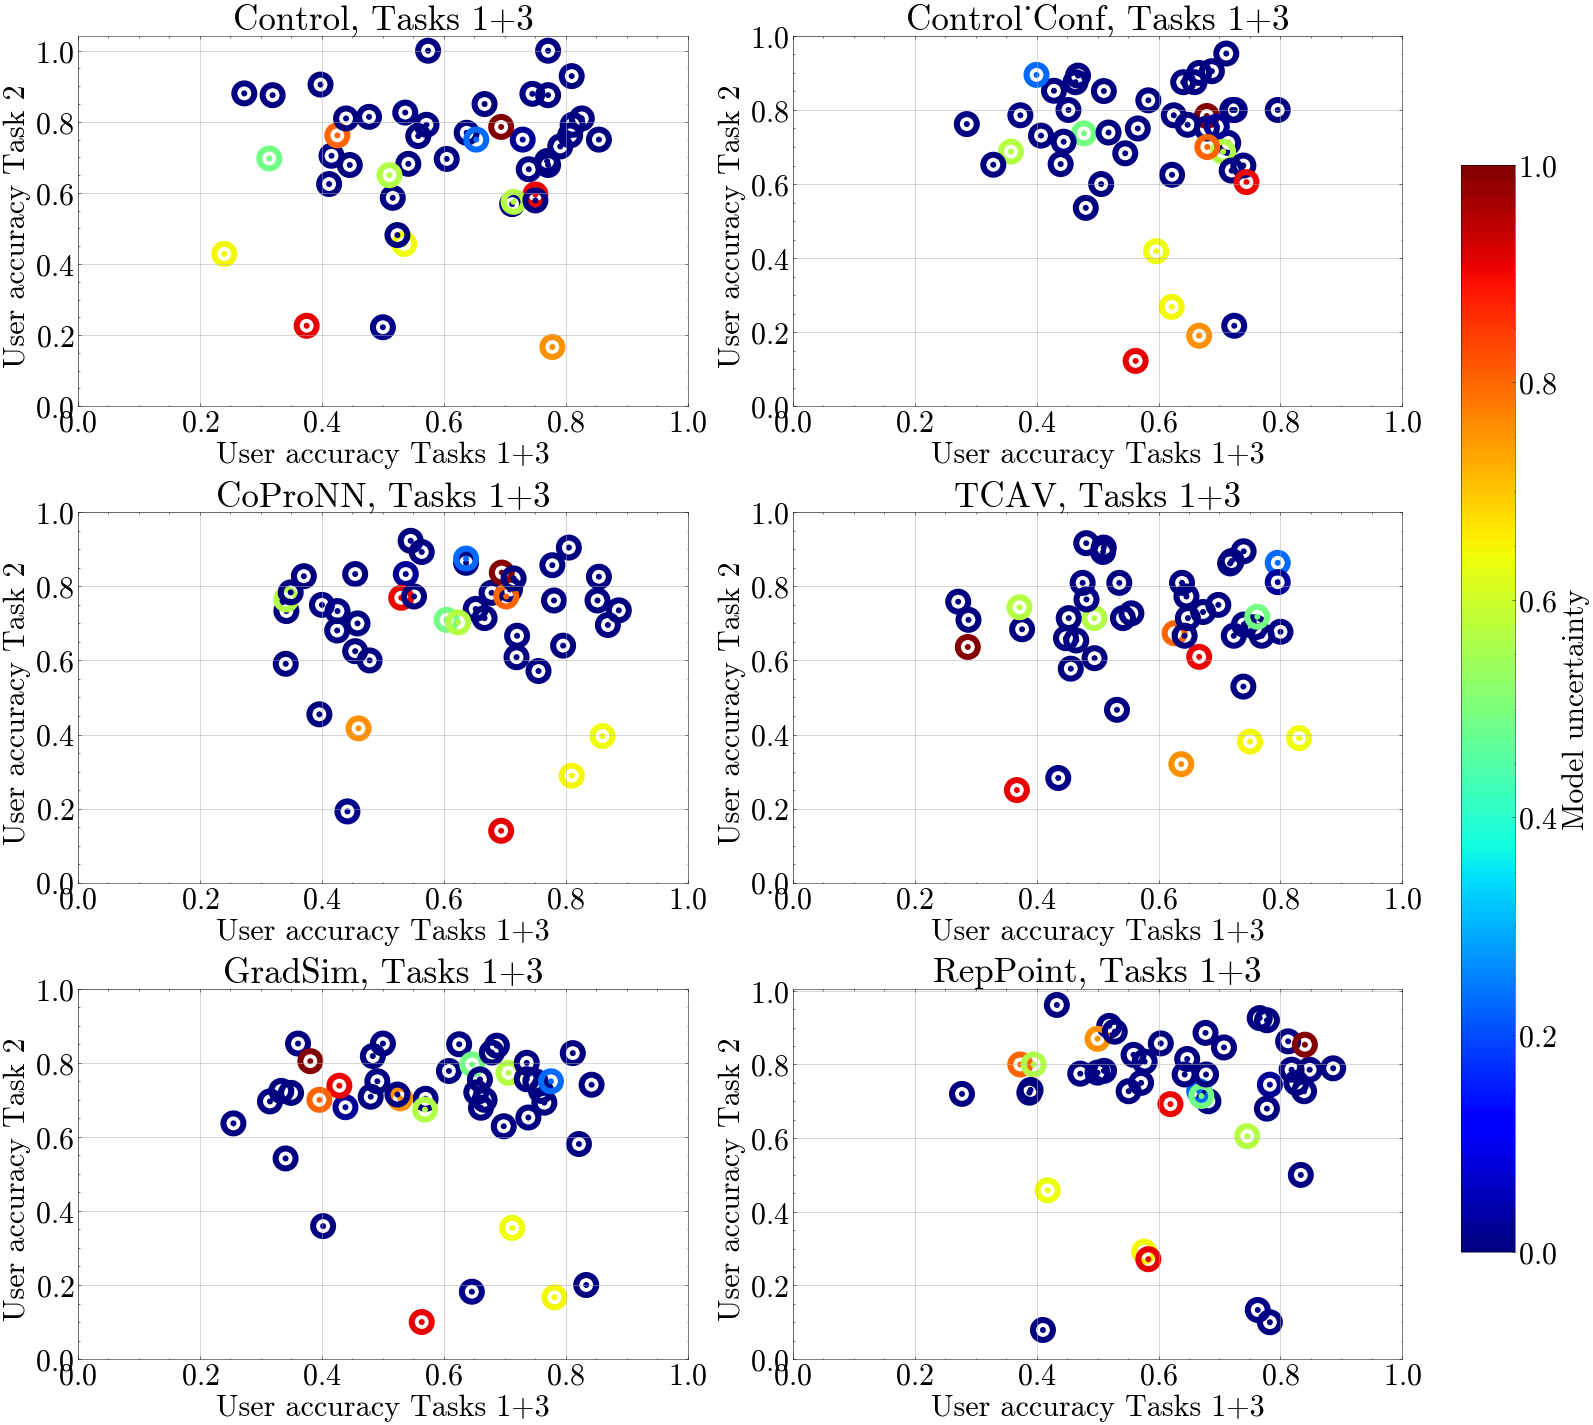

In [15]:
# Plot user_acc T13 vs user_Acc T2 and model_uncert color-coded
fontsize = 30
num_rows, num_cols = 3, 2
fig, axs = plt.subplots(num_rows, num_cols, figsize = (20,20), layout='tight')
norm = plt.Normalize(0.0, 1.0)

for i, group in enumerate(uncert_points_per_group['Tasks 1+3']):
    plt.subplot(num_rows, num_cols, i+1)
    plt.scatter(x = uncert_points_per_group['Tasks 1+3'][group]['User_Acc'], 
                y = uncert_points_per_group['Task 2'][group]['User_Acc'],
                c = plt.cm.jet(norm(uncert_points_per_group['Task 2'][group]['Model_Uncert'])), lw = 20)
                # Note: model uncertainty is the same for all tasks
    plt.xlabel('User accuracy Tasks 1+3', fontsize = fontsize)
    plt.ylabel('User accuracy Task 2 ', fontsize = fontsize)
    plt.xticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    plt.yticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    if i < 2:
        plt.title(group + ', ' + task_name, fontsize = fontsize+5)
    elif i == 2:
        plt.title('CoProNN, ' + task_name, fontsize = fontsize+5)
    else:
        plt.title(group.split('_')[1] + ', ' + task_name, fontsize = fontsize+5) 
    plt.grid()
    
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.jet), ax = axs, 
                    orientation='vertical', location = 'right', anchor=(3.0, 0.0))
cbar.ax.tick_params(labelsize=fontsize)
cbar.set_label('Model uncertainty', fontsize = fontsize)

plt.savefig('../figures/toloka/user_acc.png', bbox_inches='tight')
plt.show()

C:\Users\Teo\AppData\Local\Temp/ipykernel_13836/3107663737.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('../figures/toloka/user_uncert.png', bbox_inches='tight')


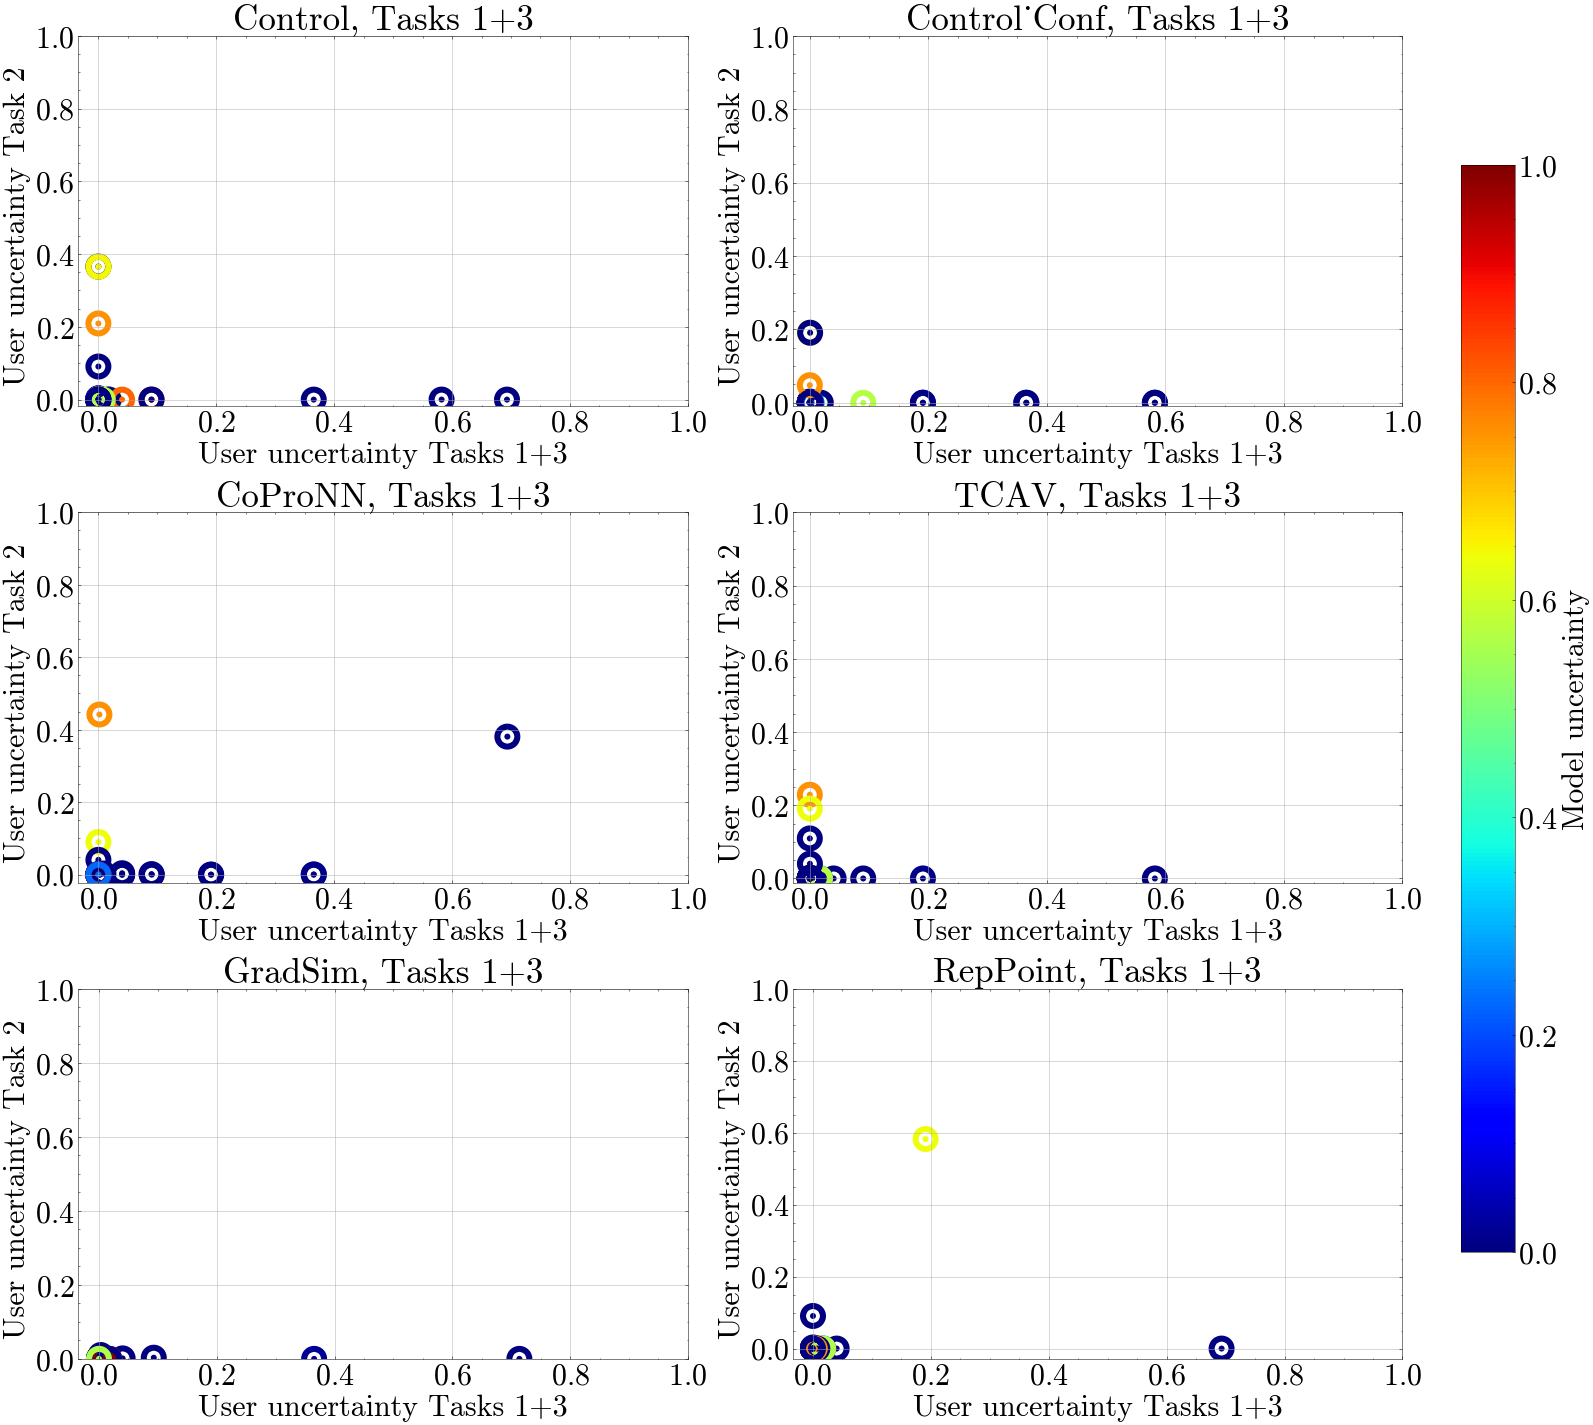

In [38]:
# Plot user_uncert T13 vs user_uncert T2 and model_uncert color-coded
fontsize = 30
num_rows, num_cols = 3, 2
fig, axs = plt.subplots(num_rows, num_cols, figsize = (20,20), layout='tight')
norm = plt.Normalize(0.0, 1.0)

for i, group in enumerate(uncert_points_per_group['Tasks 1+3']):
    plt.subplot(num_rows, num_cols, i+1)
    plt.scatter(x = uncert_points_per_group['Tasks 1+3'][group]['User_Uncert'], 
                y = uncert_points_per_group['Task 2'][group]['User_Uncert'],
                c = plt.cm.jet(norm(uncert_points_per_group['Task 2'][group]['Model_Uncert'])), lw = 20)
                # Note: model uncertainty is the same for all tasks
    plt.xlabel('User uncertainty Tasks 1+3', fontsize = fontsize)
    plt.ylabel('User uncertainty Task 2 ', fontsize = fontsize)
    plt.xticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    plt.yticks(np.arange(0.0, 1.05, 0.2), fontsize = fontsize)
    if i < 2:
        plt.title(group + ', ' + task_name, fontsize = fontsize+5)
    elif i == 2:
        plt.title('CoProNN, ' + task_name, fontsize = fontsize+5)
    else:
        plt.title(group.split('_')[1] + ', ' + task_name, fontsize = fontsize+5) 
    plt.grid()
    
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.jet), ax = axs, 
                    orientation='vertical', location = 'right', anchor=(3.0, 0.0))
cbar.ax.tick_params(labelsize=fontsize)
cbar.set_label('Model uncertainty', fontsize = fontsize)

plt.savefig('../figures/toloka/user_uncert.png', bbox_inches='tight')
plt.show()

### User Accuracies 

In [8]:
# Get accuracies per tasks
task_stats = {'Control':           {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Control_Conf':      {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Concepts_KNN':      {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Concepts_TCAV':     {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Examples_GradSim':  {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Examples_RepPoint': {'Task_1': [], 'Task_2': [], 'Task_3': []}}
for group in stats:
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):

        t1, t2, t3 = user.iloc[:10, :], user.iloc[10:20, :], user.iloc[20:30, :]
        task_stats[group]['Task_1'].append((t1['OUTPUT:result'] == t1['GOLDEN:result']).sum())
        task_stats[group]['Task_2'].append((t2['OUTPUT:result'] == t2['GOLDEN:result']).sum())
        task_stats[group]['Task_3'].append((t3['OUTPUT:result'] == t3['GOLDEN:result']).sum())

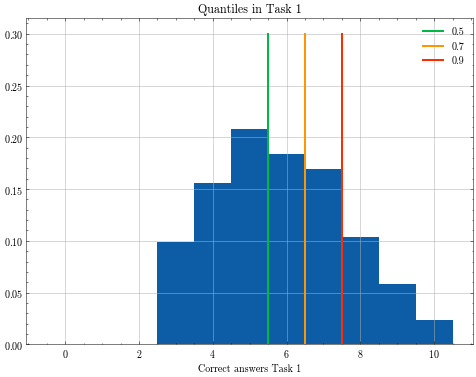

In [8]:
# Plot scores in Task 1 for all groups together
corrects_1 = task_stats['Control']['Task_1'] + task_stats['Control_Conf']['Task_1'] + \
             task_stats['Concepts_KNN']['Task_1'] + task_stats['Concepts_TCAV']['Task_1'] + \
             task_stats['Examples_GradSim']['Task_1'] + task_stats['Examples_RepPoint']['Task_1']

# Compute various quantiles
qs = [0.5, 0.7, 0.9]
corrects_1_q = [np.quantile(corrects_1, q) for q in qs]

# Plot histogram of scores for all users in Task 1
plt.figure(figsize=(8, 6))
plt.hist(corrects_1, bins = np.arange(num_samples_per_task+2)-0.5, density = True)
for cq in corrects_1_q:
    plt.plot([cq-0.5, cq-0.5], [0.0, 0.3], lw=2)
plt.xlabel('Correct answers Task 1')
plt.title('Quantiles in Task 1')
plt.legend(qs)
plt.grid()
plt.show()

The median over all answers in Task 1 lies at 6 correct answers.

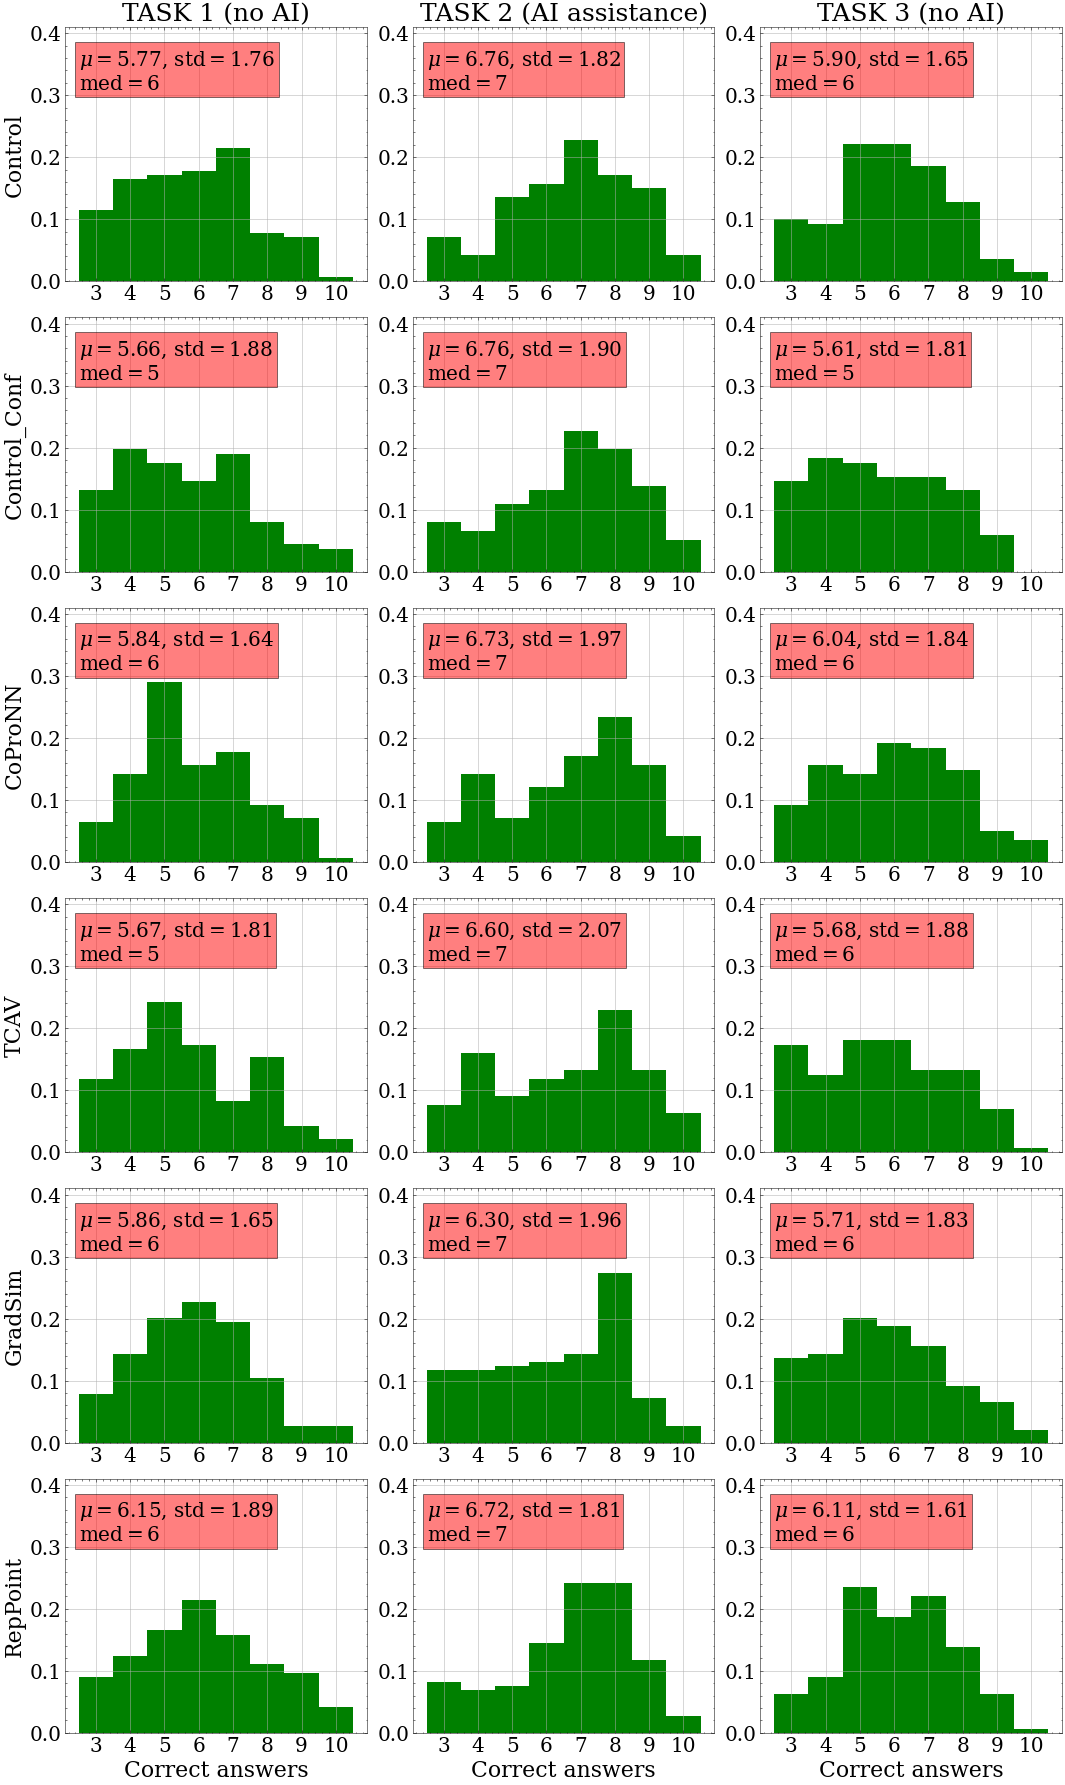

In [32]:
fontsize = 20
plt.figure(figsize=(15, 25))
for j, group in enumerate(task_stats):
    for i, task in enumerate(task_stats[group]):

        plt.subplot(len(task_stats), 3, 3*j+i+1)
        n, _, patches = plt.hist(task_stats[group][task],
                                 bins = np.arange(3, num_samples_per_task+2)-0.5, density = True, color = 'green')
        #plt.setp(patches[-4:], 'facecolor', 'green')
        if j == 5: plt.xlabel('Correct answers', fontsize=fontsize+2)
        plt.ylim(0.0, 0.41)
        task_type = " (AI assistance)" if i == 1 else " (no AI)"
        if j == 0: plt.title(task.replace('_', ' ').upper() + task_type, fontsize=fontsize+5)

        if i % 3 == 0: 
            if j < 2:
                plt.ylabel(group, fontsize = fontsize+2)
            elif j == 2:
                plt.ylabel('CoProNN', fontsize = fontsize+2)
            else:
                plt.ylabel(group.split('_')[1], fontsize = fontsize+2) 
        plt.xticks(np.arange(3,11), fontsize=fontsize); plt.yticks([0.0, 0.1, 0.2, 0.3, 0.4], fontsize=fontsize)
        
        avg = np.mean(task_stats[group][task])
        med = np.median(task_stats[group][task])
        std = np.std(task_stats[group][task])
        legend_str = '\n'.join((r'$\mu=%.2f$' % (avg, ) + ', '
                                r'$\mathrm{std}=%.2f$' % (std, ),
                                r'$\mathrm{med}=%.0f$' % (med, )))
        plt.text(2.5, 0.31, legend_str, fontsize = fontsize, bbox = dict(facecolor = 'red', alpha = 0.5))
        plt.grid()
plt.tight_layout()
plt.savefig('../figures/toloka/user_acc_hist_std.png', bbox_inches='tight')
plt.show()

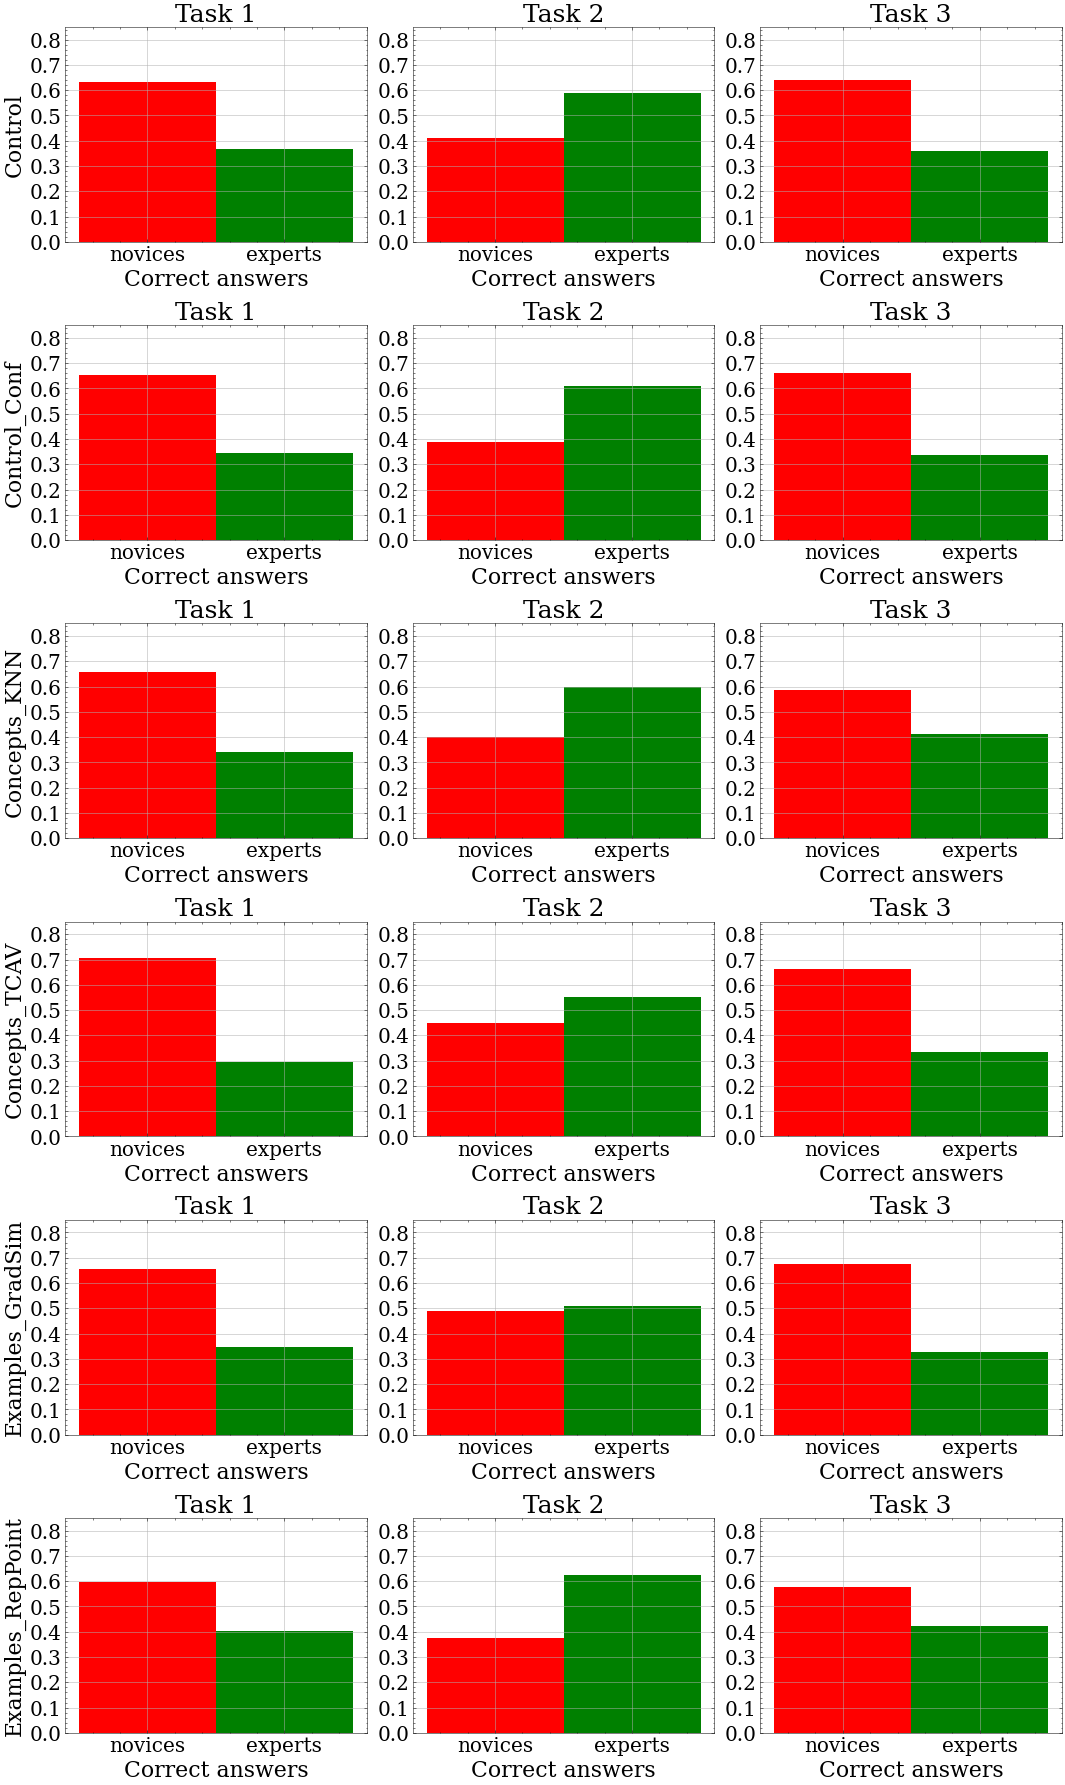

In [6]:
# Novices-Experts split w.r.t. median
fontsize = 20
plt.figure(figsize=(15, 25))
for j, group in enumerate(task_stats):
    for i, task in enumerate(task_stats[group]):

        plt.subplot(len(task_stats), 3, 3*j+i+1)
        num_novices = np.count_nonzero(np.asarray(task_stats[group][task]) < 7)
        nov_exp_ticks = ['novices'] * num_novices \
                        + ['experts'] * ((stats[group]['ASSIGNMENT:assignment_id'].nunique())-1 - num_novices)
        n, _, patches = plt.hist(nov_exp_ticks, bins = np.arange(3)-0.5, density = True, color = 'red')
        plt.setp(patches[1], 'facecolor', 'green')
        plt.xlabel('Correct answers', fontsize=fontsize+2)
        plt.ylim(0.0, 0.85)
        plt.title(task.replace('_', ' '), fontsize=fontsize+5)
        if i % 3 == 0: plt.ylabel(group,  fontsize=fontsize+2)
        plt.xticks(fontsize=fontsize); plt.yticks(fontsize=fontsize)
        plt.grid()
plt.tight_layout()
plt.show()

### Agreement Rate

In [7]:
# One-based indexes Tasks 1+3:
loaded_soft = np.load('./beexplainable/metafiles/Bees/masked/5_species/softmax_preds.npy')
IMAGES_PATH = './beexplainable/metafiles/Bees/masked/images_5_cleaned.txt'
classes = ['bicolor', 'flavipes', 'fulva']
from beexplainable.beexplainable.utils import metafile_readers as mr
img_dict = mr.metafile_to_dict(IMAGES_PATH)
for img_id in img_dict: # remove parent species folder name
    img_dict[img_id] = img_dict[img_id].split('/')[1]
img_dict['1']

'Andrena_bicolor_2799379_1.jpg'

In [8]:
# How often did users agree with the AI's hints in Task 1
print('Agreement TASK 1')
for group in stats:
    agree_rate_t1 = 0.0
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):
        t1 = user.iloc[:10,:]
        model_preds_t1 = []
        for img in t1['INPUT:image']:
            substr = img.split('/')[-1].split('.')[0].split('-')[:4]
            orig_name = '_'.join(substr) + '.jpg'
            orig_id = list(img_dict.keys())[list(img_dict.values()).index(orig_name)]
            pred_cls = np.argmax(loaded_soft[int(orig_id)-1], axis=-1)
            if pred_cls < 3: # model can recognize more species than shown to the user
                model_preds_t1.append(classes[ pred_cls ])
            else:
                model_preds_t1.append(None)

        agree_rate_t1 += (model_preds_t1 == t1['OUTPUT:result']).sum()
    print(group + ': users agreed ' + str(np.round(agree_rate_t1/num_users[group]*10, 2)) + '% of the times with the AI.')

Agreement TASK 1
Control: users agreed 55.93% of the times with the AI.
Control_Conf: users agreed 54.01% of the times with the AI.
Concepts_KNN: users agreed 55.39% of the times with the AI.
Concepts_TCAV: users agreed 55.21% of the times with the AI.
Examples_GradSim: users agreed 55.0% of the times with the AI.
Examples_RepPoint: users agreed 56.62% of the times with the AI.


In [9]:
# How often did users agree with the AI's hints in Task 2
print('Agreement TASK 2')
for group in stats:
    agree_rate_t2 = 0.0
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):
        t2 = user.iloc[10:20,:]
        model_preds_t2 = []
        for img in t2['INPUT:image']:
            substr = img.split('/')[-1].split('.')[0].split('-')[:4]
            orig_name = '_'.join(substr) + '.jpg'
            orig_id = list(img_dict.keys())[list(img_dict.values()).index(orig_name)]
            pred_cls = np.argmax(loaded_soft[int(orig_id)-1], axis=-1)
            model_preds_t2.append(classes[ pred_cls ])

        agree_rate_t2 += (model_preds_t2 == t2['OUTPUT:result']).sum()
    print(group + ': users agreed ' + str(np.round(agree_rate_t2/num_users[group]*10, 2)) + '% of the times with the AI.')

Agreement TASK 2
Control: users agreed 68.71% of the times with the AI.
Control_Conf: users agreed 70.22% of the times with the AI.
Concepts_KNN: users agreed 69.22% of the times with the AI.
Concepts_TCAV: users agreed 66.94% of the times with the AI.
Examples_GradSim: users agreed 71.17% of the times with the AI.
Examples_RepPoint: users agreed 76.41% of the times with the AI.


In [10]:
# How often did users agree with the AI's hints in Task 2, when they were wrong
print('Agreement TASK 2 WRONG')
for group in stats:
    agree_rate_t2_w, total_wrong = 0.0, 0
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):
        t2 = user.iloc[10:20,:]
        for i, img in enumerate(t2['INPUT:image']):
            if 'wrong' in img:
                total_wrong += 1
                substr = img.split('/')[-1].split('.')[0].split('-')[:4]
                orig_name = '_'.join(substr) + '.jpg'
                orig_id = list(img_dict.keys())[list(img_dict.values()).index(orig_name)]
                pred_cls = np.argmax(loaded_soft[int(orig_id)-1], axis=-1)
                if classes[pred_cls] in t2.iloc[i]['OUTPUT:result']:
                    agree_rate_t2_w += 1

    print(group + ': users agreed ' + str(np.round(agree_rate_t2_w/total_wrong*100, 2)) + '% of the times with the WRONG AI hint.')
    print(str(total_wrong) + ' of the ' + str(10*num_users[group]) + ' images in Task 2 had a wrong AI prediction.\n')

Agreement TASK 2 WRONG
Control: users agreed 47.29% of the times with the WRONG AI hint.
277 of the 1400 images in Task 2 had a wrong AI prediction.

Control_Conf: users agreed 52.31% of the times with the WRONG AI hint.
260 of the 1370 images in Task 2 had a wrong AI prediction.

Concepts_KNN: users agreed 47.67% of the times with the WRONG AI hint.
279 of the 1410 images in Task 2 had a wrong AI prediction.

Concepts_TCAV: users agreed 45.25% of the times with the WRONG AI hint.
263 of the 1440 images in Task 2 had a wrong AI prediction.

Examples_GradSim: users agreed 62.95% of the times with the WRONG AI hint.
305 of the 1540 images in Task 2 had a wrong AI prediction.

Examples_RepPoint: users agreed 69.1% of the times with the WRONG AI hint.
288 of the 1450 images in Task 2 had a wrong AI prediction.



In [11]:
# How often did users agree with the AI's hints in Task 3
print('Agreement TASK 3')
for group in stats:
    agree_rate_t3 = 0.0
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):
        t3 = user.iloc[20:30,:]
        model_preds_t3 = []
        for img in t3['INPUT:image']:
            substr = img.split('/')[-1].split('.')[0].split('-')[:4]
            orig_name = '_'.join(substr) + '.jpg'
            orig_id = list(img_dict.keys())[list(img_dict.values()).index(orig_name)]
            pred_cls = np.argmax(loaded_soft[int(orig_id)-1], axis=-1)
            if pred_cls < 3: # model can recognize more species than shown to the user
                model_preds_t3.append(classes[ pred_cls ])
            else:
                model_preds_t3.append(None)

        agree_rate_t3 += (model_preds_t3 == t3['OUTPUT:result']).sum()
    print(group + ': users agreed ' + str(np.round(agree_rate_t3/num_users[group]*10, 2)) + '% of the times with the AI.')

Agreement TASK 3
Control: users agreed 56.57% of the times with the AI.
Control_Conf: users agreed 52.85% of the times with the AI.
Concepts_KNN: users agreed 56.45% of the times with the AI.
Concepts_TCAV: users agreed 54.17% of the times with the AI.
Examples_GradSim: users agreed 53.9% of the times with the AI.
Examples_RepPoint: users agreed 57.66% of the times with the AI.


### Most Difficult Samples (DEPRECATED)

In [12]:
img_acc_dict = {}
for group in stats:
    for img_link, img_group in stats[group].groupby(by='INPUT:image'):
        img_key = img_link.split('/')[-1]
        num_corrects = np.count_nonzero(img_group['OUTPUT:result'] == img_group['GOLDEN:result'])
        if img_key not in img_acc_dict: img_acc_dict[img_key] = []
        img_acc_dict[img_key].append((num_corrects, len(img_link)))
img_acc_dict

{'Andrena-bicolor-39411385-1-hard-corr.jpg': [(41, 65),
  (23, 65),
  (45, 65),
  (22, 65),
  (44, 65),
  (26, 65),
  (44, 65),
  (29, 65),
  (48, 65),
  (34, 65),
  (54, 65),
  (23, 65)],
 'Andrena-flavipes-75178065-1-hard-wrong.jpg': [(48, 67),
  (18, 67),
  (57, 67),
  (11, 67),
  (55, 67),
  (13, 67),
  (62, 67),
  (16, 67),
  (57, 67),
  (8, 67),
  (57, 67),
  (14, 67)],
 'Andrena-fulva-20995537-1-easy.jpg': [(19, 58),
  (24, 58),
  (15, 58),
  (27, 58),
  (12, 58),
  (25, 58),
  (16, 58),
  (25, 58),
  (19, 58),
  (37, 58),
  (22, 58),
  (27, 58)],
 'Andrena-flavipes-18165663-1-easy.jpg': [(17, 61),
  (12, 61),
  (17, 61),
  (14, 61),
  (22, 61),
  (15, 61),
  (24, 61),
  (15, 61),
  (13, 61),
  (18, 61),
  (19, 61),
  (15, 61)],
 'Andrena-fulva-43172780-1-easy.jpg': [(37, 58),
  (20, 58),
  (36, 58),
  (19, 58),
  (19, 58),
  (34, 58),
  (39, 58),
  (22, 58),
  (35, 58),
  (23, 58),
  (33, 58),
  (23, 58)],
 'Andrena-fulva-70388239-1-easy.jpg': [(37, 58),
  (19, 58),
  (35, 58),

In [13]:
print(str(len(img_acc_dict)) + ' images in total.')

45 images in total.


In [14]:
accuracies = []
for img_key in img_acc_dict:
    total_ratio = [0, 0]
    for group_ratio in img_acc_dict[img_key]:
        total_ratio[0] += group_ratio[0]
        total_ratio[1] += group_ratio[1]
    acc = np.round(total_ratio[0]/total_ratio[1], 2)
    accuracies.append(acc)
    print(img_key + ': ' + str(acc))
    if acc > 0.5:
        print('Acc > 0.5')
        #os.remove("./beexplainable/toloka/bees/images/task13_imgs/" + img_key.replace('-', '_'))

Andrena-bicolor-39411385-1-hard-corr.jpg: 0.56
Acc > 0.5
Andrena-flavipes-75178065-1-hard-wrong.jpg: 0.52
Acc > 0.5
Andrena-fulva-20995537-1-easy.jpg: 0.39
Andrena-flavipes-18165663-1-easy.jpg: 0.27
Andrena-fulva-43172780-1-easy.jpg: 0.49
Andrena-fulva-70388239-1-easy.jpg: 0.52
Acc > 0.5
Andrena-bicolor-39748872-3-easy.jpg: 0.34
Andrena-bicolor-71835166-1-easy.jpg: 0.34
Andrena-flavipes-11582465-1-hard-corr.jpg: 0.67
Acc > 0.5
Andrena-flavipes-5795371-2-easy.jpg: 0.46
Andrena-flavipes-22101904-1-easy.jpg: 0.51
Acc > 0.5
Andrena-fulva-78595111-1-hard-wrong.jpg: 0.28
Andrena-fulva-16795311-1-easy.jpg: 0.5
Andrena-bicolor-42078638-2-hard-wrong.jpg: 0.39
Andrena-fulva-71290622-1-easy.jpg: 0.45
Andrena-flavipes-40178244-1-easy.jpg: 0.48
Andrena-bicolor-2799379-1-easy.jpg: 0.37
Andrena-flavipes-91695281-1-hard-corr.jpg: 0.49
Andrena-fulva-83947290-1-hard-wrong.jpg: 0.69
Acc > 0.5
Andrena-flavipes-70512188-3-hard-corr.jpg: 0.62
Acc > 0.5
Andrena-fulva-101552423-1-easy.jpg: 0.45
Andrena-fulva-

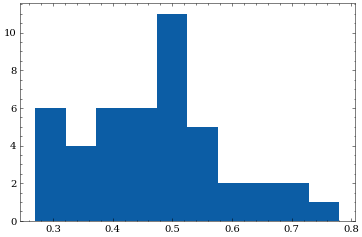

In [15]:
plt.hist(accuracies);